In [1]:
import sys; sys.path.append("..")
import warnings, joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
from sklearn.cluster import KMeans
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LinearRegression
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from src.features import get_splits
from src.segments import segment_matrix, fit_segments, assign_segments, name_segment

X_train, X_test, y_train, y_test = get_splits("../data/raw/telco_churn.csv")

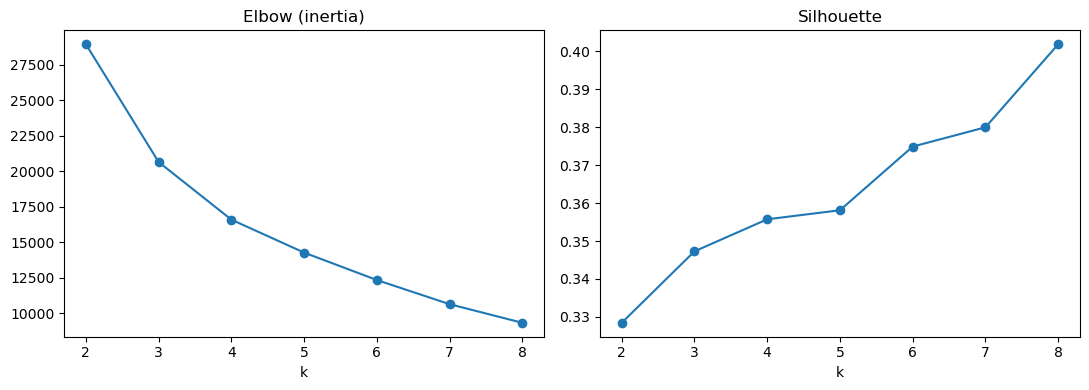

   k  inertia  silhouette
0  2  28934.0       0.328
1  3  20641.0       0.347
2  4  16585.0       0.356
3  5  14266.0       0.358
4  6  12334.0       0.375
5  7  10634.0       0.380
6  8   9324.0       0.402


In [2]:
S_tr = segment_matrix(X_train)
Z = StandardScaler().fit_transform(S_tr)
ks, inertia, sil = range(2, 9), [], []
for k in ks:
    m = KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z)
    inertia.append(m.inertia_)
    sil.append(silhouette_score(Z, m.labels_, sample_size=3000, random_state=42))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(ks, sil, "o-"); ax[1].set_title("Silhouette"); ax[1].set_xlabel("k")
plt.tight_layout()
plt.savefig("../reports/figures/kmeans_k_selection.png", dpi=150); plt.show()
print(pd.DataFrame({"k": list(ks), "inertia": np.round(inertia), "silhouette": np.round(sil, 3)}))

In [5]:
scaler, km = fit_segments(X_train, k=4)
seg = assign_segments(X_train, scaler, km)

prof = S_tr.copy(); prof["segment"] = seg; prof["churn"] = y_train.values
table = prof.groupby("segment").mean().round(2)
table["customers"] = prof["segment"].value_counts().sort_index()
table["name"] = table.apply(name_segment, axis=1)
table[["tenure", "MonthlyCharges", "addon_count", "contract_len", "churn", "customers", "name"]]

,tenure,MonthlyCharges,addon_count,contract_len,churn,customers,name
segment,,,,,,,
0,30.22,21.11,0.00,1.07,0.07,1214,No-internet / phone only
1,57.79,87.52,4.32,1.43,0.10,1530,Loyal power users
2,18.18,49.79,1.62,0.23,0.28,1179,"Mid-value, month-to-month"
3,21.32,86.24,1.79,0.08,0.54,1711,"New fiber, month-to-month"


In [6]:
joblib.dump((scaler, km), "../models/segments.joblib")

['../models/segments.joblib']

In [7]:
Z = scaler.transform(S_tr)
iso = IsolationForest(n_estimators=300, contamination=0.02, random_state=42).fit(Z)
flag = iso.predict(Z) == -1

print("flagged:", flag.sum(), "of", len(flag))
print("churn rate, flagged: %.3f | not flagged: %.3f" % (y_train[flag].mean(), y_train[~flag].mean()))
print("two-year contracts among flagged:", (X_train[flag]["Contract"] == "Two year").sum())
S_tr[flag].describe().loc[["mean", "min", "max"]].round(1)

flagged: 113 of 5634
churn rate, flagged: 0.071 | not flagged: 0.269
two-year contracts among flagged: 92


,tenure,MonthlyCharges,addon_count,streaming_flag,has_support_addons,contract_len,fiber,no_internet
mean,54.3,65.8,2.5,0.3,0.6,1.8,0.5,0.0
min,0.0,25.4,0.0,0.0,0.0,0.0,0.0,0.0
max,72.0,116.2,6.0,1.0,1.0,2.0,1.0,1.0


In [8]:
svc = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
       "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
D = pd.get_dummies(X_train[svc], drop_first=True).astype(float)
lr = LinearRegression().fit(D, X_train["MonthlyCharges"])
resid = X_train["MonthlyCharges"] - lr.predict(D)

print("R2: %.4f | residual std: %.2f | max |residual|: %.2f" % (
    lr.score(D, X_train["MonthlyCharges"]), resid.std(), resid.abs().max()))
quint = pd.qcut(resid, 5, duplicates="drop")
pd.DataFrame({"churn": y_train.values}).groupby(quint.values)["churn"].mean().round(3)

R2: 0.9988 | residual std: 1.03 | max |residual|: 4.81


(-4.243, -0.764]    0.289
(-0.764, -0.231]    0.271
(-0.231, 0.214]     0.250
(0.214, 0.771]      0.249
(0.771, 4.808]      0.267
Name: churn, dtype: float64